for some advices train your model first with all ur data and then u can use dimensionality reduction to speed up training or filter some noise

and also help to vizualize your data into 2 dimension and help u advance in communication with non data scientist

in this chapter we will see the curse of dimensionality and we will look into projection and manifold learning and after that to pca , random projection and locally linear embedding (lle)

CURSE OF DIMENSIONALITY

highdimensional datasets are at risk of being very sparse
in short the more dimension the training dataset had the more is risky to overfit

Projection

if we had points represented in 3D ,we can make an plane and do a projection of every point in this plane

tada! we just reduced the dimesion from 3D to 2D

Manifold learning

but projection is not the best approach ,the subspace may turn and twist , such as the famous swiss roll toy set 

In [7]:

import numpy as np
from scipy.spatial.transform import Rotation

m = 60
X = np.zeros((m, 3))  # initialize 3D dataset
rng = np.random.default_rng(seed=42)
angles = (rng.random(m) ** 3 + 0.5) * 2 * np.pi  # uneven distribution
X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5  # oval
X += 0.28 * rng.standard_normal((m, 3))  # add more noise
X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)
X += [0.2, 0, 0.2]  # shift a bit

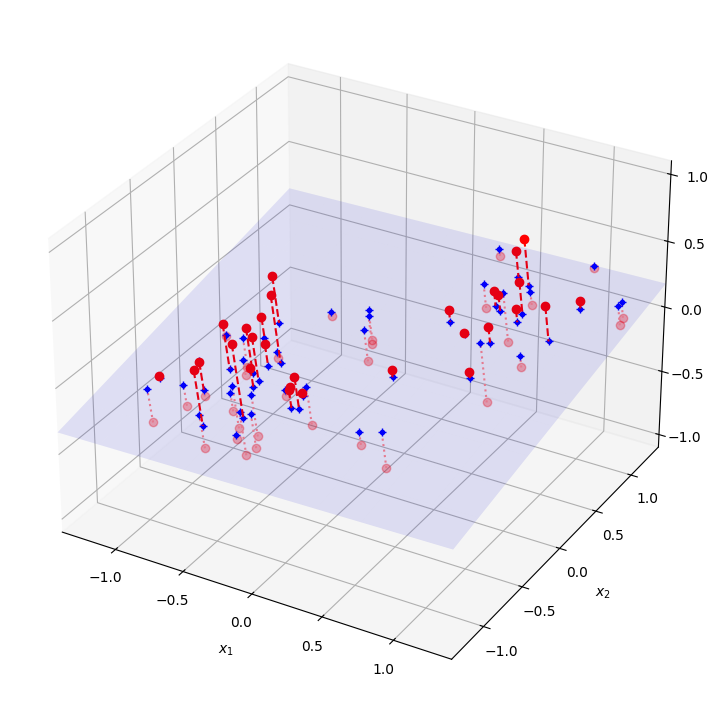

In [8]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X2D = pca.fit_transform(X)  # dataset reduced to 2D
X3D_inv = pca.inverse_transform(X2D)  # 3D position of the projected samples
X_centered = X - X.mean(axis=0)
U, s, Vt = np.linalg.svd(X_centered)

axes = [-1.4, 1.4, -1.4, 1.4, -1.1, 1.1]
x1, x2 = np.meshgrid(np.linspace(axes[0], axes[1], 10),
                     np.linspace(axes[2], axes[3], 10))
w1, w2 = np.linalg.solve(Vt[:2, :2], Vt[:2, 2])  # projection plane coefs
z = w1 * (x1 - pca.mean_[0]) + w2 * (x2 - pca.mean_[1]) - pca.mean_[2]  # plane
X3D_above = X[X[:, 2] >= X3D_inv[:, 2]]  # samples above plane
X3D_below = X[X[:, 2] < X3D_inv[:, 2]]  # samples below plane

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")

# plot samples and projection lines below plane first
ax.plot(X3D_below[:, 0], X3D_below[:, 1], X3D_below[:, 2], "ro", alpha=0.3)
for i in range(m):
    if X[i, 2] < X3D_inv[i, 2]:
        ax.plot([X[i][0], X3D_inv[i][0]],
                [X[i][1], X3D_inv[i][1]],
                [X[i][2], X3D_inv[i][2]], ":", color="#F88")

ax.plot_surface(x1, x2, z, alpha=0.1, color="b")  # projection plane
ax.plot(X3D_inv[:, 0], X3D_inv[:, 1], X3D_inv[:, 2], "b+")  # projected samples
ax.plot(X3D_inv[:, 0], X3D_inv[:, 1], X3D_inv[:, 2], "b.")

# now plot projection lines and samples above plane
for i in range(m):
    if X[i, 2] >= X3D_inv[i, 2]:
        ax.plot([X[i][0], X3D_inv[i][0]],
                [X[i][1], X3D_inv[i][1]],
                [X[i][2], X3D_inv[i][2]], "r--")

ax.plot(X3D_above[:, 0], X3D_above[:, 1], X3D_above[:, 2], "ro")

def set_xyz_axes(ax, axes):
    ax.xaxis.set_rotate_label(False)
    ax.yaxis.set_rotate_label(False)
    ax.zaxis.set_rotate_label(False)
    ax.set_xlabel("$x_1$", labelpad=8, rotation=0)
    ax.set_ylabel("$x_2$", labelpad=8, rotation=0)
    ax.set_zlabel("$x_3$", labelpad=8, rotation=0)
    ax.set_xlim(axes[0:2])
    ax.set_ylim(axes[2:4])
    ax.set_zlim(axes[4:6])

set_xyz_axes(ax, axes)
ax.set_zticks([-1, -0.5, 0, 0.5, 1])


plt.show()

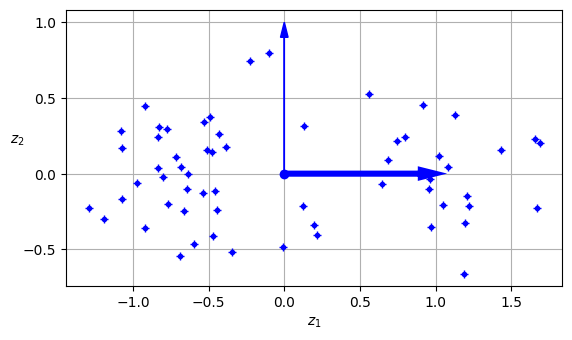

In [9]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, aspect='equal')
ax.plot(X2D[:, 0], X2D[:, 1], "b+")
ax.plot(X2D[:, 0], X2D[:, 1], "b.")
ax.plot([0], [0], "bo")
ax.arrow(0, 0, 1, 0, head_width=0.05, length_includes_head=True,
         head_length=0.1, fc='b', ec='b', linewidth=4)
ax.arrow(0, 0, 0, 1, head_width=0.05, length_includes_head=True,
         head_length=0.1, fc='b', ec='b', linewidth=1)
ax.set_xlabel("$z_1$")
ax.set_yticks([-0.5, 0, 0.5, 1])
ax.set_ylabel("$z_2$", rotation=0)
ax.set_axisbelow(True)
ax.grid(True)

In [1]:
from sklearn.datasets import make_swiss_roll

X_swiss, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)

In [5]:
X_swiss.shape

(1000, 3)

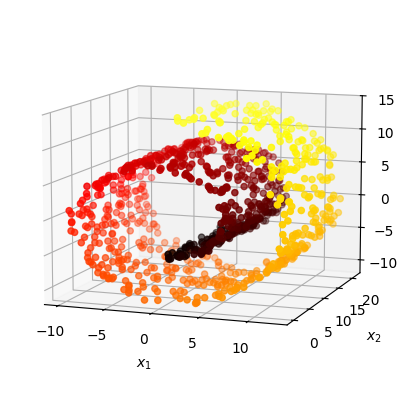

In [10]:
from matplotlib.colors import ListedColormap

darker_hot = ListedColormap(plt.cm.hot(np.linspace(0, 0.8, 256)))

axes = [-11.5, 14, -2, 23, -12, 15]

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_swiss[:, 0], X_swiss[:, 1], X_swiss[:, 2], c=t, cmap=darker_hot)
ax.view_init(10, -70)
set_xyz_axes(ax, axes)
plt.show()

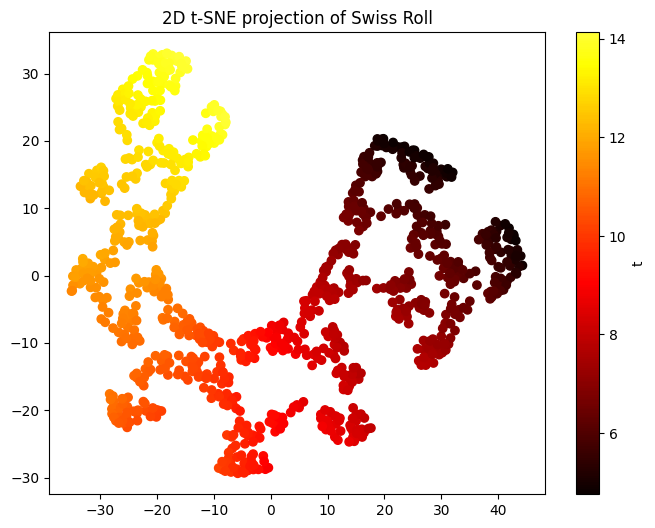

In [11]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_swiss)


darker_hot = ListedColormap(plt.cm.hot(np.linspace(0, 0.8, 256)))

plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=t, cmap=darker_hot)
plt.title("2D t-SNE projection of Swiss Roll")
plt.colorbar(label='t')

simply the projection will make the points squash different layers

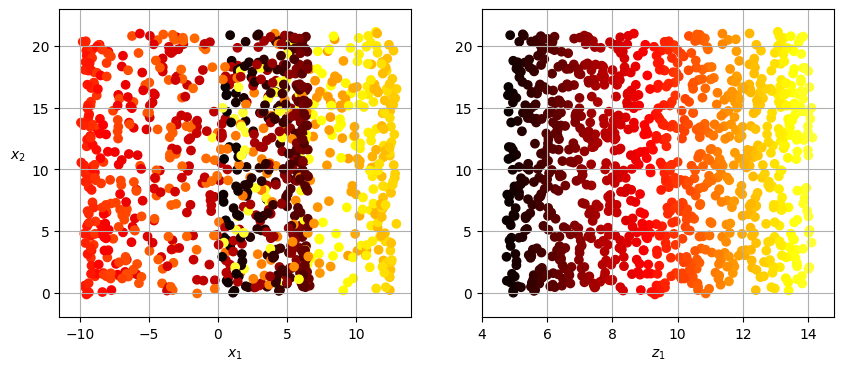

In [7]:
plt.figure(figsize=(10, 4))

plt.subplot(121)
plt.scatter(X_swiss[:, 0], X_swiss[:, 1], c=t, cmap=darker_hot)
plt.axis(axes[:4])
plt.xlabel("$x_1$")
plt.ylabel("$x_2$", labelpad=10, rotation=0)
plt.grid(True)

plt.subplot(122)
plt.scatter(t, X_swiss[:, 1], c=t, cmap=darker_hot)
plt.axis([4, 14.8, axes[2], axes[3]])
plt.xlabel("$z_1$")
plt.grid(True)

plt.show()

manifold is continous data point and that can be reduced from 2D to 1D

high dimensional data lies to low dimensional manifold

for nearset neighbor we want to classify point on which manifold innit 

then we use the nearest neighbor between two points x1 and x2 and the nearest neighbot between two manifols actualy belong, it is hard,then we can approximale manifold with his tangest on x1,and meseaure the distance between two tangent planes 

tangentprop is similiary to data augmentation ,it regularize the model to know the perturbation of the model 

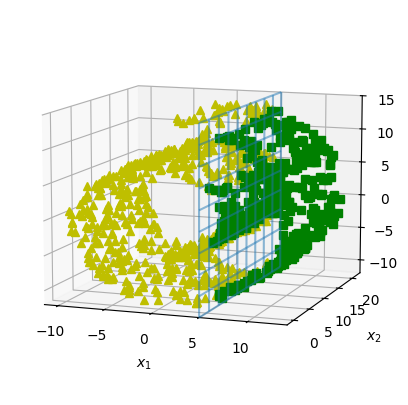

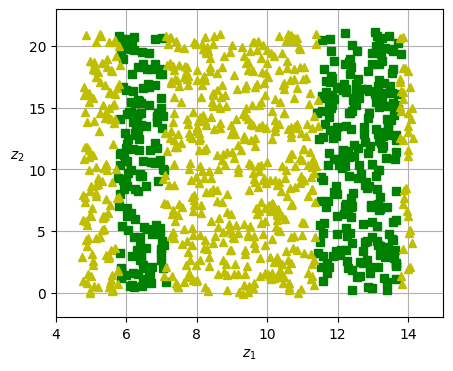

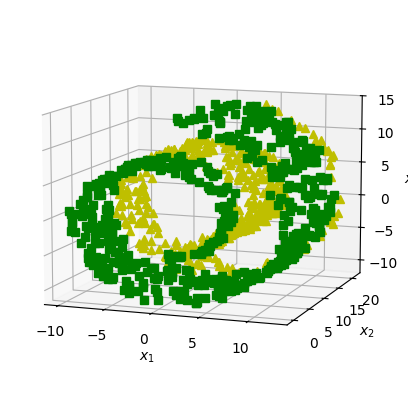

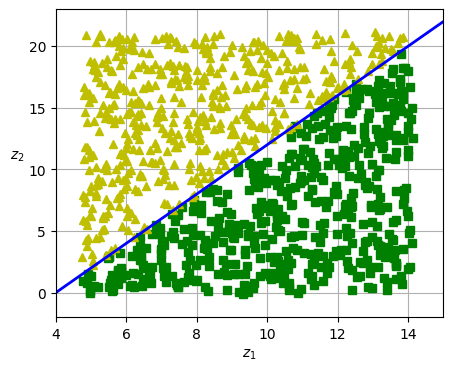

In [8]:
axes = [-11.5, 14, -2, 23, -12, 15]
x2s = np.linspace(axes[2], axes[3], 10)
x3s = np.linspace(axes[4], axes[5], 10)
x2, x3 = np.meshgrid(x2s, x3s)

positive_class = X_swiss[:, 0] > 5
X_pos = X_swiss[positive_class]
X_neg = X_swiss[~positive_class]

fig = plt.figure(figsize=(6, 5))
ax = plt.subplot(1, 1, 1, projection='3d')
ax.view_init(10, -70)
ax.plot(X_neg[:, 0], X_neg[:, 1], X_neg[:, 2], "y^")
ax.plot_wireframe(5, x2, x3, alpha=0.5)
ax.plot(X_pos[:, 0], X_pos[:, 1], X_pos[:, 2], "gs")
set_xyz_axes(ax, axes)
plt.show()

fig = plt.figure(figsize=(5, 4))
ax = plt.subplot(1, 1, 1)
ax.plot(t[positive_class], X_swiss[positive_class, 1], "gs")
ax.plot(t[~positive_class], X_swiss[~positive_class, 1], "y^")
ax.axis([4, 15, axes[2], axes[3]])
ax.set_xlabel("$z_1$")
ax.set_ylabel("$z_2$", rotation=0, labelpad=8)
ax.grid(True)
plt.show()

positive_class = 2 * (t[:] - 4) > X_swiss[:, 1]
X_pos = X_swiss[positive_class]
X_neg = X_swiss[~positive_class]

fig = plt.figure(figsize=(6, 5))
ax = plt.subplot(1, 1, 1, projection='3d')
ax.view_init(10, -70)
ax.plot(X_neg[:, 0], X_neg[:, 1], X_neg[:, 2], "y^")
ax.plot(X_pos[:, 0], X_pos[:, 1], X_pos[:, 2], "gs")
ax.xaxis.set_rotate_label(False)
ax.yaxis.set_rotate_label(False)
ax.zaxis.set_rotate_label(False)
ax.set_xlabel("$x_1$", rotation=0)
ax.set_ylabel("$x_2$", rotation=0)
ax.set_zlabel("$x_3$", rotation=0)
ax.set_xlim(axes[0:2])
ax.set_ylim(axes[2:4])
ax.set_zlim(axes[4:6])
plt.show()

fig = plt.figure(figsize=(5, 4))
ax = plt.subplot(1, 1, 1)
ax.plot(t[positive_class], X_swiss[positive_class, 1], "gs")
ax.plot(t[~positive_class], X_swiss[~positive_class, 1], "y^")
ax.plot([4, 15], [0, 22], "b-", linewidth=2)
ax.axis([4, 15, axes[2], axes[3]])
ax.set_xlabel("$z_1$")
ax.set_ylabel("$z_2$", rotation=0, labelpad=8)
ax.grid(True)
plt.show()

PCA

principal component analysis first it identifies first the hyperplane that lies closest to the data ,and then it project the data into it like the earlier examople

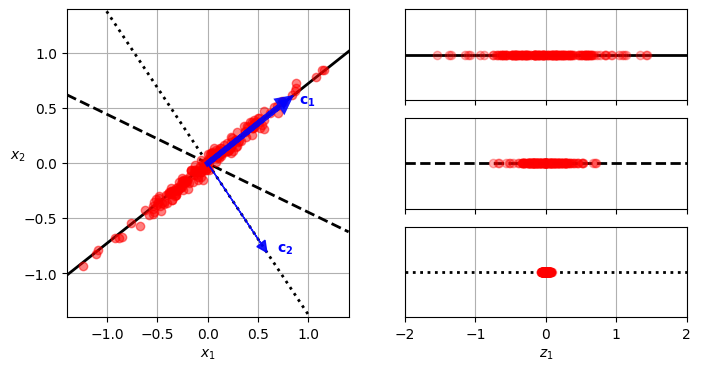

In [9]:
angle = np.pi / 5
stretch = 5
m = 200

np.random.seed(3)
X_line = np.random.randn(m, 2) / 10
X_line = X_line @ np.array([[stretch, 0], [0, 1]])  # stretch
X_line = X_line @ [[np.cos(angle), np.sin(angle)],
                   [np.sin(angle), np.cos(angle)]]  # rotate

u1 = np.array([np.cos(angle), np.sin(angle)])
u2 = np.array([np.cos(angle - 2 * np.pi / 6), np.sin(angle - 2 * np.pi / 6)])
u3 = np.array([np.cos(angle - np.pi / 2), np.sin(angle - np.pi / 2)])

X_proj1 = X_line @ u1.reshape(-1, 1)
X_proj2 = X_line @ u2.reshape(-1, 1)
X_proj3 = X_line @ u3.reshape(-1, 1)

plt.figure(figsize=(8, 4))
plt.subplot2grid((3, 2), (0, 0), rowspan=3)
plt.plot([-1.4, 1.4], [-1.4 * u1[1] / u1[0], 1.4 * u1[1] / u1[0]], "k-",
         linewidth=2)
plt.plot([-1.4, 1.4], [-1.4 * u2[1] / u2[0], 1.4 * u2[1] / u2[0]], "k--",
         linewidth=2)
plt.plot([-1.4, 1.4], [-1.4 * u3[1] / u3[0], 1.4 * u3[1] / u3[0]], "k:",
         linewidth=2)
plt.plot(X_line[:, 0], X_line[:, 1], "ro", alpha=0.5)
plt.arrow(0, 0, u1[0], u1[1], head_width=0.1, linewidth=4, alpha=0.9,
          length_includes_head=True, head_length=0.1, fc="b", ec="b", zorder=10)
plt.arrow(0, 0, u3[0], u3[1], head_width=0.1, linewidth=1, alpha=0.9,
          length_includes_head=True, head_length=0.1, fc="b", ec="b", zorder=10)
plt.text(u1[0] + 0.1, u1[1] - 0.05, r"$\mathbf{c_1}$", color="blue")
plt.text(u3[0] + 0.1, u3[1], r"$\mathbf{c_2}$", color="blue")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$", rotation=0)
plt.axis([-1.4, 1.4, -1.4, 1.4])
plt.grid()

plt.subplot2grid((3, 2), (0, 1))
plt.plot([-2, 2], [0, 0], "k-", linewidth=2)
plt.plot(X_proj1[:, 0], np.zeros(m), "ro", alpha=0.3)
plt.gca().get_yaxis().set_ticks([])
plt.gca().get_xaxis().set_ticklabels([])
plt.axis([-2, 2, -1, 1])
plt.grid()

plt.subplot2grid((3, 2), (1, 1))
plt.plot([-2, 2], [0, 0], "k--", linewidth=2)
plt.plot(X_proj2[:, 0], np.zeros(m), "ro", alpha=0.3)
plt.gca().get_yaxis().set_ticks([])
plt.gca().get_xaxis().set_ticklabels([])
plt.axis([-2, 2, -1, 1])
plt.grid()

plt.subplot2grid((3, 2), (2, 1))
plt.plot([-2, 2], [0, 0], "k:", linewidth=2)
plt.plot(X_proj3[:, 0], np.zeros(m), "ro", alpha=0.3)
plt.gca().get_yaxis().set_ticks([])
plt.axis([-2, 2, -1, 1])
plt.xlabel("$z_1$")
plt.grid()

plt.show()

before you project you have to select the right hyperplane to do the projection,

we can see that the top graph has high variance,and then the variance reduces from top to bottom

its seems like we have to choose the axis with the higher variance

PRINCIPAL COMPONENT

pca identifies the axis with the highest variance and then the second that orthogonal to the second and after that we can go forward if we higher dimension data 

the ith axis is called the ith principal component

In [10]:
X = np.random.randn(3,100)
X_centered  = X - X.mean(axis=0)
U , S , vT  = np.linalg.svd(X_centered)

c1 = vT[0]
c2 = vT[1]

In [11]:
X.shape

(3, 100)

In [12]:
c1.shape

(100,)

In [13]:
s = np.argsort(S)
S,s   # the s already sorted

(array([1.11952216e+01, 9.59665678e+00, 2.41711463e-15]), array([2, 1, 0]))

projecting down to d dimensions

In [14]:
W2  = vT[:2].T

X2D = X_centered @ W2

In [15]:
W2lambda = list(map(lambda x : x>=0.9,s))
W2lambda

[np.True_, np.True_, np.False_]

In [16]:
S

array([1.11952216e+01, 9.59665678e+00, 2.41711463e-15])

In [17]:
W2lambda1 = list(filter(lambda x : x>=1,S))
W2lambda1

[np.float64(11.195221590896347), np.float64(9.596656783460206)]

In [18]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X2D = pca.fit_transform(X)

the hypothis tell us to select the variance greater that 70% or eigenvalues greater than 1

In [19]:
pca.explained_variance_ratio_

array([0.57643229, 0.42356771])

In [20]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784',as_frame=False)

X_train , y_train = mnist.data[:60000] , mnist.target[:60000]
X_test , y_test = mnist.data[60000:] , mnist.target[60000:]

In [21]:
pca  = PCA()
pca.fit(X_train)
cumsum = np.cumsum(pca.explained_variance_ratio_)
d = np.argmax(cumsum>=0.95)  +1

In [22]:
d

np.int64(154)

In [23]:
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_train)
pca.n_components_

np.int64(154)

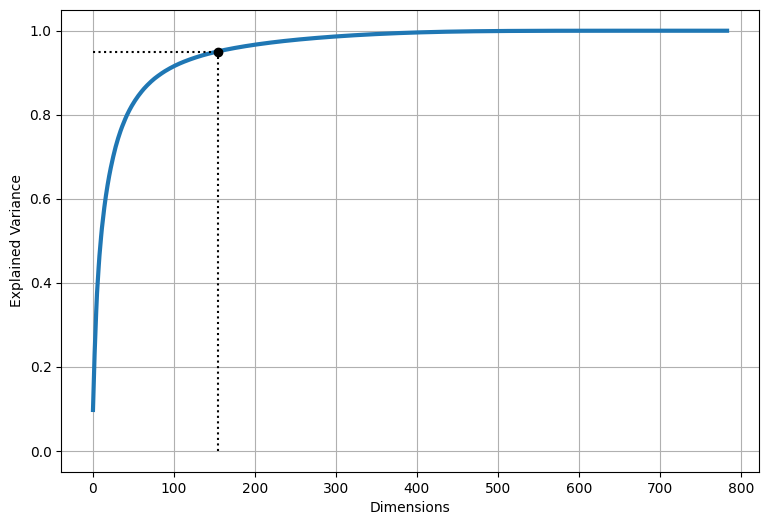

In [24]:
plt.figure(figsize = (9,6))
plt.plot(cumsum,linewidth=3)
plt.xlabel("Dimensions")
plt.ylabel("Explained Variance")
plt.plot([d, d], [0, 0.95], "k:")
plt.plot([0, d], [0.95, 0.95], "k:")
plt.plot(d,0.95,"ko")
plt.grid()
plt.show()

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline

clf = make_pipeline(PCA(random_state=42)
                    ,RandomForestClassifier(random_state=42))

param_distrib = {"pca__n_components":np.arange(0.70,0.95),
                  "randomforestclassifier__n_estimators":np.arange(50,500)}

rnd_search = RandomizedSearchCV(clf,param_distrib,n_iter=10,cv=3,random_state=42)

rnd_search.fit(X_train[:10_000],y_train[:10_000])

KeyboardInterrupt: 

In [ ]:
rnd_search.best_params_

{'randomforestclassifier__n_estimators': np.int64(457),
 'pca__n_components': np.float64(0.7)}

PCA FOR COMPRESSION

In [ ]:
X_recovered = pca.inverse_transform(X_reduced)

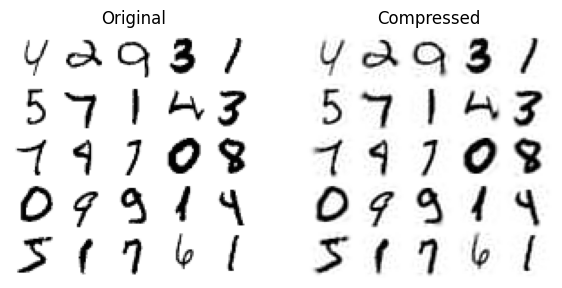

In [ ]:
plt.figure(figsize=(7, 4))
for idx, X in enumerate((X_train[::2100], X_recovered[::2100])):
    plt.subplot(1, 2, idx + 1)
    plt.title(["Original", "Compressed"][idx])
    for row in range(5):
        for col in range(5):
            plt.imshow(X[row * 5 + col].reshape(28, 28), cmap="binary",
                       vmin=0, vmax=255, extent=(row, row + 1, col, col + 1))
            plt.axis([0, 5, 0, 5])
            plt.axis("off")

Randomized Search

In [ ]:
rnd_pca = PCA(n_components= 154,svd_solver="randomized",random_state=42)
X_reduced = rnd_pca.fit_transform(X_train)

By default, svd_solver is actually set to "auto": Scikit-Learn automatically uses the
randomized PCA algorithm if max(m, n) > 500 and n_components is an integer smaller
than 80% of min(m, n), or else it uses the full SVD approach. So the preceding code
would use the randomized PCA algorithm even if you removed the
svd_solver="randomized" argument, since 154 < 0.8 × 784. If you want to force
Scikit-Learn to use full SVD for a slightly more precise result, you can set the
svd_solver hyperparameter to "full".

Incremental PCA

In [ ]:
from sklearn.decomposition import IncrementalPCA

n_batches = 10
ipca = IncrementalPCA(n_components=154)

for i,X_batch in enumerate(np.array_split(X_train,n_batches)):
    print(f"------------The {i+1}th batch--------")
    ipca.partial_fit(X_batch)

X_reduced = ipca.transform(X_train)

------------The 1th batch--------
------------The 2th batch--------
------------The 3th batch--------
------------The 4th batch--------
------------The 5th batch--------
------------The 6th batch--------
------------The 7th batch--------
------------The 8th batch--------
------------The 9th batch--------
------------The 10th batch--------


In [ ]:
filename = "my_mnist.mmap"
X_mmap = np.memmap(filename, dtype='float32', mode='write',
shape=X_train.shape)
X_mmap[:] = X_train # could be a loop instead, saving the data chunk by chunk
X_mmap.flush()

In [ ]:
X_mmap = np.memmap(filename, dtype="float32", mode="readonly").reshape(-1,
784)
batch_size = X_mmap.shape[0] // n_batches
ipca = IncrementalPCA(n_components=154, batch_size=batch_size)
ipca.fit(X_mmap)

IncrementalPCA(batch_size=6000, n_components=154)

RANDOM PROJECTION

solve the slow of pca that is for images and big datasets is not practicly used

use random linear projection,in research the 2 points if they're close or different ,in the projection it remain the same status ,but if u reduce the dimension too much you lost more information about data

if u have dataset m = 5,000 instances with n = 20,000 features each ,and you dont want the squared distance to change by more than ε = 10% ,then you must project the data down to d dimensions >= 4log(m) / (½ ε² - ⅓ ε³),wich is 7300 dimensions

In [ ]:
from sklearn.random_projection import johnson_lindenstrauss_min_dim

m=5000
e=0.1

d=johnson_lindenstrauss_min_dim(m,eps=e)
d

np.int64(7300)

Now we can just generate a random matrix P of shape [d, n], where each
item is sampled randomly from a Gaussian distribution with mean 0 and
variance 1 / d, and use it to project a dataset from n dimensions down to d

In [ ]:
n = 20_000
np.random.seed(42)
P = np.random.randn(d, n) / np.sqrt(d)
X = np.random.randn(m, n)
X_reduced = X @ P.T

In [ ]:
from sklearn.random_projection import GaussianRandomProjection
gaussian_rnd_proj = GaussianRandomProjection(eps=e, random_state=42)
X_reduced = gaussian_rnd_proj.fit_transform(X)

there's also a sparse method that u generate a matrix distribution with much sparsity and you can reduce the memory by that

each cell in random matrix has a probability r of being nonzero and each nonzero is either -v or v

v = 1/√dr.

Computing the pseudo-inverse may take a very long time if the components matrix is
large, as the computational complexity of pinv() is O(dn²) if d < n, or O(nd²) otherwise.

In [ ]:
components_pinv = np.linalg.pinv(gaussian_rnd_proj.components_)
X_recovered = X_reduced @ components_pinv.T

In summary, random projection is a simple, fast, memory-efficient, and
surprisingly powerful dimensionality reduction algorithm that you should
keep in mind, especially when you deal with high-dimensional datasets.

LLE

locally linear embedding is non linear dimensionality reduction (NLDR) technique ,it is an manifold learning technique that does not rely on projection,lle works by first measuring how each instance in the training set is linear relatad to his nearest neighbors ,and then looking for a low dimensional representation of set where these local relationship are best preserved,this approach make it good at unrolling twisted manifolds 

In [ ]:
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import LocallyLinearEmbedding

X_swiss, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10, random_state=42)
X_unrolled = lle.fit_transform(X_swiss)

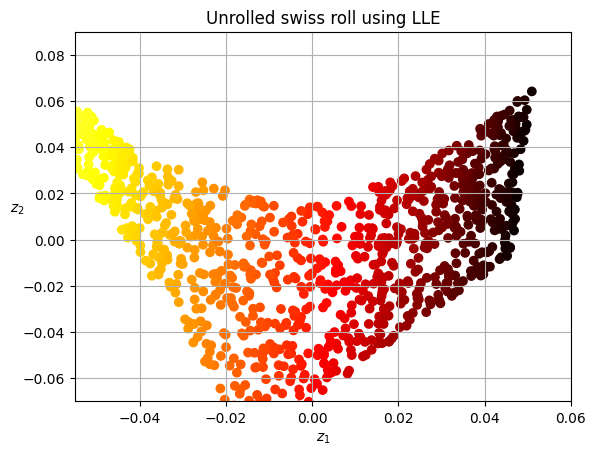

In [ ]:
plt.scatter(X_unrolled[:, 0], X_unrolled[:, 1],
            c=t, cmap=darker_hot)
plt.xlabel("$z_1$")
plt.ylabel("$z_2$", rotation=0)
plt.axis([-0.055, 0.060, -0.070, 0.090])
plt.grid(True)
plt.title("Unrolled swiss roll using LLE")
plt.show()

O(m log(m)n log(k)) for finding the k-nearset-neighbor ,O(mnk3) for optimizing the weights

and O(dm2) for constructing the low dimensional representations 

for pca there's also an linear kernel to reduce the dimensionalitu for nonlinear dayta

the first step in pca is centring the data ,and then calculate the convariance matrix ,eigenvector decomposition found by singular value decomposition (svd), for correlation XT X, and projection for fourth step 

MDS

multi dimensional scaling use the delta's for our data ,similiarity measure on how instance's are similiar ,and dissimiliarity measure the distance between two instances and mds use the dissimiliarity , and the matrix is symmetric then we can use just the the highest part of our matrix of dissimiliarity 

we have three categories classical (PCoA),metric ,non metric

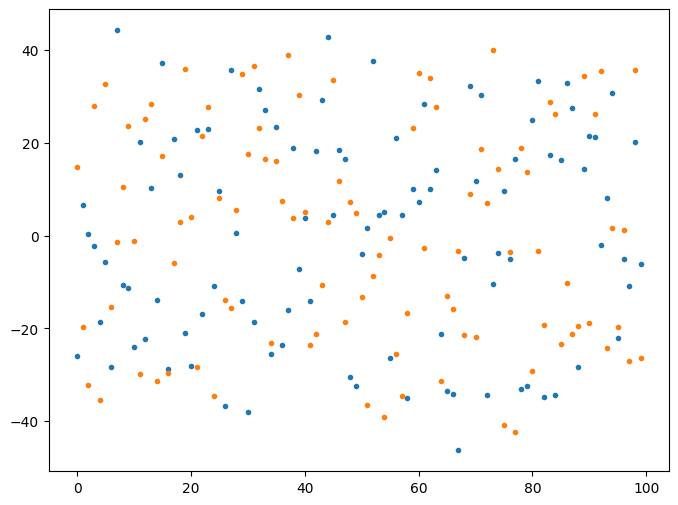

In [27]:
from sklearn.manifold import MDS
from sklearn.datasets import load_digits

X,_ = load_digits(return_X_y=True)
mds = MDS(n_components=2)
X_reduced = mds.fit_transform(X[:100])
plt.figure(figsize=(8,6))
plt.plot(X_reduced,".")
plt.show()

1compute gram matrix
2eigen decomposition
3projection

the distance is the dot product of the difference's between the matrix multiply by the transpose

the inner product is equal to <xi,xj> = (1/2(normxi + normxj + di,j **2))

gram matrix is symmetry and real then we can do the eigen decomposition just for the metrix distance's 

S = VLVt  then X=V*S**(1/2)  (the square root of S is the the eigendecomposition but we do the square root for l because gram matrix is definite positive then we do the sqqure root for each element in the diagonal)

Metric MDS

the most used

there's a lot of metric distance ,then this method is more generalazed

distance need to be positive and symmetry and satisfy the triangle inequality

and if it doesnt verify the triangle inequality then the distance is not metric

its an iterative method

1  initialize random points in the low dimensional space 

2   mesure the distance in this configuration

3   calcute the loss stress

4   gradient descent to minimaze the loss function stress

stress is the sum square difference between the distance of lowdimensional space and the actual distance

stress stand for standardized residual sum of squares and then we scale it because is sensitive by the sumi<j di,j and then we apply the square root

De leeuw mulitply by weights

sammon mapping

the stress function is not convex use smacof (sklearn also use that)

how we choose the optimal dimension d

there's two stratigies 

first we have only the positive eigenvalue of the gram matrix because if we use a distance that is not metric the gram is no longer definite positive

second if (stress(d-1) - stress(d))/stress(d-1) < 5% we stop 

small 𝑑
d → high bias (high stress),

large 𝑑
d → low bias but high variance / no structure.

In [12]:
from sklearn.datasets import load_wine

data = load_wine()
features = data["data"]
labels = data["target"]
features.shape

(178, 13)

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

try:
  import ipyvolume as ipv
except:
  !pip install ipyvolume -q
  import ipyvolume as ipv
  !jupyter nbextension enable --py --sys-prefix ipyvolume

def visualize_2d(x, labels):
    sns.scatterplot(x=x[:, 0], y=x[:, 1], hue=labels, s=100, alpha=0.8,
                    palette="Greens", edgecolor="black")

def visualize_3d(x, labels):
    # Workaround as axis limits are not auto-scaling
    x_norm = (x - x.min(axis=0)) / (x.max(axis=0) - x.min(axis=0))
    fig = ipv.figure(height=800, width=600)
    x, y, z = x_norm[:, 0], x_norm[:, 1], x_norm[:, 2]

    # Colors
    cmap = plt.get_cmap('Greens', 3)
    color = cmap(labels)
    ipv.scatter(x, y, z, size=4, marker="sphere", color=color)
    ipv.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 44.8 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 56.1 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 81.2 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 80.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 260.7/260.7 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.7/271.7 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 54.5 MB/s eta 0:00:00
Enabling notebook extension ipyvolume/extension...
      - Validating: OK


In [14]:
from sklearn.metrics.pairwise import manhattan_distances

d_matrix = manhattan_distances(features)
d_matrix

array([[  0.  ,  51.06, 152.48, ..., 257.14, 249.41, 558.28],
       [ 51.06,   0.  , 148.3 , ..., 257.98, 250.55, 521.18],
       [152.48, 148.3 ,   0.  , ..., 384.76, 376.83, 649.14],
       ...,
       [257.14, 257.98, 384.76, ...,   0.  ,   8.15, 306.74],
       [249.41, 250.55, 376.83, ...,   8.15,   0.  , 312.09],
       [558.28, 521.18, 649.14, ..., 306.74, 312.09,   0.  ]])

Distance matrix of the first 10 data points...


<Axes: >

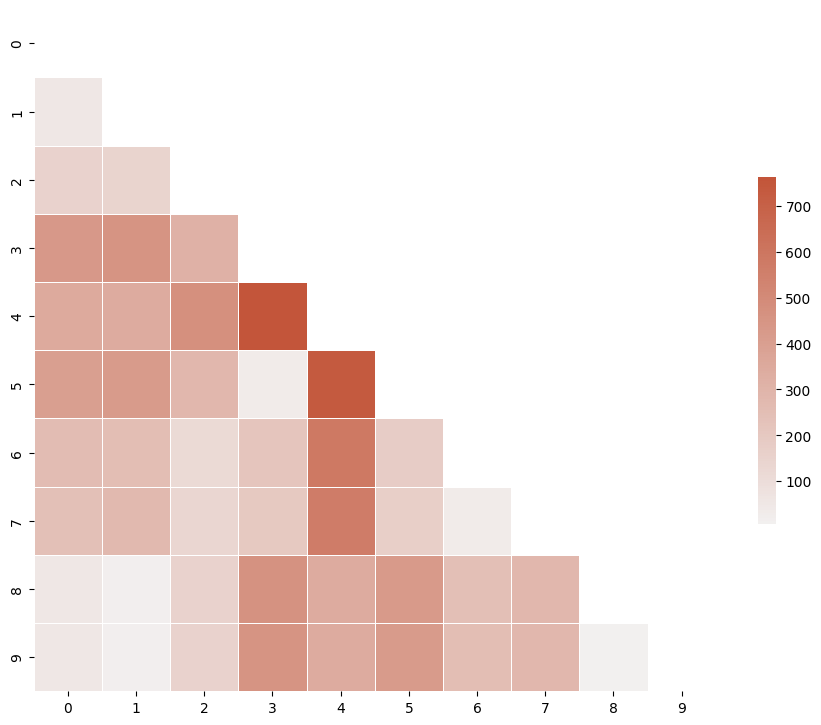

In [15]:
import seaborn as sns
import numpy as np
print("Distance matrix of the first 10 data points...")
distances = d_matrix[:10, :10]

mask = np.triu(np.ones_like(distances, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(distances, mask=mask, cmap=cmap, vmax=distances.max(), center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [16]:
from sklearn.manifold import MDS

mds = MDS(n_components=3,
          normalized_stress=False,
          metric=True,
          dissimilarity="precomputed",
          random_state=42,
          eps=1e-09)
%time mds_3d = mds.fit_transform(d_matrix)
visualize_3d(mds_3d,labels)

CPU times: user 715 ms, sys: 1.94 ms, total: 717 ms
Wall time: 717 ms


Html(layout=None, style_='display: none', tag='span')

Container(figure=Figure(box_center=[0.5, 0.5, 0.5], box_size=[1.0, 1.0, 1.0], camera=PerspectiveCamera(fov=45.…

In [17]:
print("mds stress: ",mds.stress_)

mds stress:  957538.6689037182


CPU times: user 892 ms, sys: 0 ns, total: 892 ms
Wall time: 907 ms


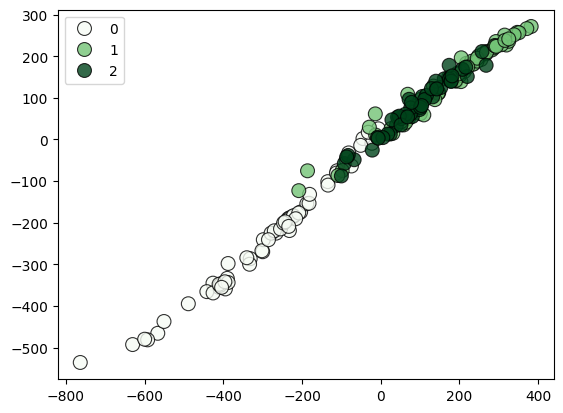

In [18]:
mds = MDS(n_components=2,
          normalized_stress=False,
          eps=1e-09)
%time mds_2d = mds.fit_transform(features)
visualize_2d(mds_2d,labels)

Non metric MDS

sort all the distances

we use an motonic function to sort our distances , and we interset in the ordinal one, and then we use the same steps for metric one

mds is for non linear and linear data and non metric is suited well for non linear data use two approaches eigendecomposition/iteration and we can apply it on clustring 

T-SNE

manifold learning technique is for non linear data ,euclidian distances is not ideal for non linear data 

t-stochastic neighbor embedding

sne paper

perplexity is how many neighbors we want to include close to us , if its high then we have an higher variance and compact clusters

perplexity(pi)=2**(H(pi))

we should the adjut the variances of each point

we can use perplexity to measure how many neighbors we include 

then how find the optimum variance of an 30 peplexity for example by binary search

an this search can paralelze for each point based on the sckit learn documentation

then we two probabilities distribution ,one for the high dimensional space,and one for the low dimensional space

then we can KL divergence to measure how the two distributions are divergent to other , kl(p||q) = Ep(log(p)/log(q))

SNE algorithm:

intialize the point randomly

compute pairwise distance (similiarities)

convert distances to conditional distibutions

perform binary search to find variance that matches the desired perplexity

optimize kl divergence for each point via gradient descent

now lets move on to t-SNE t-distributed sne

why we need impovement

lets look to crowding problem lets imagine 4 points in 2D square ,if we want to reduce the dimensionality to 1D ,we can not preserve the same distance's in one dimension because there's no space for that

the small forces make the points all together

then we generate an distribution to solve the problem in this cases,then we high the probabilities of the edges to kepp points not to close to together

in tsne we use the t-student distribution instead of the gaussian

t-distribtion has heaver tail and this allow points to be further away

we dont need an binary search , we can just choose the degree's instead of variance ,and the calculation of proba is more efficient and that make us prevent the exponential

early exaggaretion give us proper cluster ,and adaptative optimization to prevent local minima

In [20]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=3,perplexity=10,early_exaggeration=12,learning_rate='auto',init="random",n_jobs=4).fit_transform(features)
visualize_3d(tsne,labels)

Html(layout=None, style_='display: none', tag='span')

Container(figure=Figure(box_center=[0.5, 0.5, 0.5], box_size=[1.0, 1.0, 1.0], camera=PerspectiveCamera(fov=45.…

barnes-hut t-sne

make complexity from O(n**2) to O(n*log(n))

sne is connected to n body simulation from physics 

runtime is also big issue in phys

then barnes have come up with an optimization to n body

the approximation is based on divided the space into n cubic cells and summarize the particul in the center of cell and that also for tree

then its an accelaration of sne

t-sne is local technique non linear manifold and not deterministic and stochastic 

UMAP

mds for global and tsne for local

umap bothhhh

its in between

TDA topological data analysis  (homology)

simplicies

from data to simplicial complex to learn the local feature of manifold

filtration is putting balls around data and paramter epsilon to tell how much big we want a ball,that let us create simplicity

Giotto-tda py lib

persistant homology

check which trous are an important feature

graph constuction

nerve theorem ,if data is uniformaly distributed then we can approximate the manifold

isolation,bunching

we choose the number of neighbors,in sparse and dense region

then the radius can be as probabilities or graph and edges represent radius

and the ball has an exponential and non exponotienal wight decay

sum1,k = exp(-max(0,d(xi,xj)-roi)/sigmai) = log(k) ,roi = min{d(xi,xj)},d=metric (dissimiliarity) and k is number of neirest neighbor

now the problem is to simplicay the graph to represent the manifold

and what edges we choose?

b = a+at -ao at

strech the balls to have uniformaly data distribution,and weight to have edges,and merge local views

how to compare a graph ,then we compare the edge weight,compare two sparse matrix (between highdim and lowdim)

we use cross entropy

sum of e wh(e)log(wh(e)/wl(e)) + (1-wh(e))log(1-wh(e/1-wl(e)))

tsne vs umap attractive force vs repulsive force

how knn is found we use pynndescent appro O(n)

negative sampling to prevent negative edges

and spectral embedding initialization

In [ ]:
try:
  import umap.umap_ as umap
except:
  !pip install umap-learn -q
  import umap.umap_ as umap


reducer = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1, metric='euclidean')
%time umap_3d = reducer.fit_transform(features)
visualize_3d(umap_3d, labels)

In [ ]:
reducer = reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric='euclidean')
%time umap_2d = reducer.fit_transform(features)
visualize_2d(umap_2d, labels)   

In [ ]:
from sklearn.datasets import fetch_openml
from sklearn.